In [3]:
pip install torch torchvision

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/126.7 MB 7.9 MB/s eta 0:00:16
   --- ------------------------------------ 10.0/126.7 MB 37.2 MB/s eta 0:00:04
   ----- ---------------------------------- 18.6/126.7 MB 37.2 MB/s eta 0:00:03
   -------- ------------------------------- 25.4/126.7 MB 38.1 MB/s eta 0:00:03
   ----------- ---------------------------- 37.7/126.7 MB 41.7 MB/s eta 0:00:03
   ---------------- ----------------------- 52.2/126.7 MB 47.1 MB/s eta 0:00:02
   -------------------- ------------------- 66.3/126.7 MB 50.6 MB/s eta 0:00:02
   ------------------------- -------------- 82.1/126.7 MB 53.8 MB/s eta 0:00:01
   ------------------------------ --------- 97.0/126.7 MB 56.1 MB/s eta 0:00:01
   ---------------------------------- ---- 111.9/126.7 MB 58.0 MB/s eta 0:00:01
   --------------------------------------  126.6/126.

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\xaron\\AppData\\Roaming\\Python\\Python314\\site-packages\\networkx\\algorithms\\bipartite\\tests\\test_edgelist.py'
Check the permissions.


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached filelock-4.2.12-py3-none-any.whl.metadata (2.3 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached markupsafe-3.0.4-cp314-cp314-win_amd64.whl.metadata (2.8 kB)
Using cached torch-2.15.0-cp314-cp314-win_amd64.whl (126.7 MB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached filelock-4.2.12-py3-none-any.whl (222 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp314-cp314-win_amd64.whl (14 kB)

   ----------------------------------


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Якщо пакети ще не встановлені, розкоментуй рядок нижче та запусти комірку:
# !pip install onnx onnxscript onnxruntime openvino psutil

import os
import time
import gc
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import psutil
import torch
import torch.nn as nn
from torchvision import models
import onnx
import onnxruntime as ort
import openvino as ov

print(f"PyTorch:      {torch.__version__}")
print(f"ONNX:         {onnx.__version__}")
print(f"ONNX Runtime: {ort.__version__}")
print(f"OpenVINO:     {ov.__version__}")

PyTorch:      2.15.0+cpu
ONNX:         1.23.2
ONNX Runtime: 1.32.0
OpenVINO:     2026.4.1-22982-e213a147257-releases/2026/4


In [5]:
CLASSES = ["pizza", "steak", "sushi"]
ONNX_PATH = "resnet18_food.onnx"

# Відтворюємо архітектуру ResNet18 з Лабораторної роботи №3
pt_model = models.resnet18(weights=None)
pt_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(pt_model.fc.in_features, len(CLASSES))
)
pt_model.load_state_dict(torch.load("resnet18_food.pth", map_location="cpu"))
pt_model.eval()

# Тестовий вхідний тензор для трасування графа
dummy_input = torch.randn(1, 3, 224, 224, dtype=torch.float32)

# Експорт у формат ONNX
torch.onnx.export(
    pt_model,
    dummy_input,
    ONNX_PATH,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "logits": {0: "batch_size"}
    }
)

file_size_mb = os.path.getsize(ONNX_PATH) / (1024 * 1024)
print(f"Модель успішно експортовано у '{ONNX_PATH}' (розмір: {file_size_mb:.2f} МБ)")

C:\Users\xaron\AppData\Local\Temp\ipykernel_7616\3307658742.py:17: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1119 22:51:47.746000 7616 torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).
Failed to convert the model to the target version 17 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "C:\Users\xaron\AppData\Roaming\Python\Python314\site-packages\onnxscript\version_converter\__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "C:\Users\xaron\AppData\Roaming\Python\Python314\site-packages\onnxscript\version_converter\_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "C:\Users\xaron\AppData\Roaming\Python\Python314\site-packages\onnxscript\version_converter\__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_vers

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Модель успішно експортовано у 'resnet18_food.onnx' (розмір: 0.09 МБ)


In [6]:
# 1. Перевірка структури ONNX-графа
onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
print("Перевірка onnx.checker.check_model() пройшла успішно! Граф валідний.\n")

# 2. Інспекція входів та виходів через ONNX Runtime
ort_session = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])

print("=== Інформація про входи (Inputs) ===")
for inp in ort_session.get_inputs():
    print(f"Назва: '{inp.name}' | Тип: {inp.type} | Форма: {inp.shape}")

print("\n=== Інформація про виходи (Outputs) ===")
for out in ort_session.get_outputs():
    print(f"Назва: '{out.name}' | Тип: {out.type} | Форма: {out.shape}")

Перевірка onnx.checker.check_model() пройшла успішно! Граф валідний.

=== Інформація про входи (Inputs) ===
Назва: 'input' | Тип: tensor(float) | Форма: ['batch_size', 3, 224, 224]

=== Інформація про виходи (Outputs) ===
Назва: 'logits' | Тип: tensor(float) | Форма: ['batch_size', 3]


In [7]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_image(image_path):
    img_bgr = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (224, 224), interpolation=cv2.INTER_LINEAR)
    img_float = img_resized.astype(np.float32) / 255.0
    img_norm = (img_float - IMAGENET_MEAN) / IMAGENET_STD
    return np.transpose(img_norm, (2, 0, 1))[np.newaxis, ...]  # (1, 3, 224, 224)

# Беремо перше доступне зображення з папки dataset
sample_img_path = next(Path("dataset").rglob("*.jpg"))
input_np = preprocess_image(sample_img_path)
input_pt = torch.from_numpy(input_np)

# 1. Прямий прохід у PyTorch
with torch.no_grad():
    pt_logits = pt_model(input_pt).numpy()

# 2. Прямий прохід у ONNX Runtime
input_name = ort_session.get_inputs()[0].name
ort_logits = ort_session.run(None, {input_name: input_np})[0]

# 3. Обчислення числових відхилень
abs_diff = np.abs(pt_logits - ort_logits)
max_abs_diff = np.max(abs_diff)
mean_abs_diff = np.mean(abs_diff)

pt_pred = CLASSES[int(np.argmax(pt_logits))]
ort_pred = CLASSES[int(np.argmax(ort_logits))]

print(f"Тестове зображення: {sample_img_path}")
print(f"PyTorch логіти:      {np.round(pt_logits[0], 6)} -> Клас: {pt_pred}")
print(f"ONNX Runtime логіти: {np.round(ort_logits[0], 6)} -> Клас: {ort_pred}")
print(f"\nМаксимальне абсолютне відхилення (Max Abs Diff):  {max_abs_diff:.2e}")
print(f"Середнє абсолютне відхилення (Mean Abs Diff):     {mean_abs_diff:.2e}")
print(f"Збіг фінальних передбачень: {'ТАК' if pt_pred == ort_pred else 'НІ'}")

Тестове зображення: dataset\pizza\1008844.jpg
PyTorch логіти:      [ 0.179789 -0.202879 -0.951443] -> Клас: pizza
ONNX Runtime логіти: [ 0.179789 -0.202879 -0.951441] -> Клас: pizza

Максимальне абсолютне відхилення (Max Abs Diff):  1.43e-06
Середнє абсолютне відхилення (Mean Abs Diff):     6.80e-07
Збіг фінальних передбачень: ТАК


In [8]:
# Ініціалізація OpenVINO Core та компіляція моделі під CPU
core = ov.Core()
ov_model = core.read_model(ONNX_PATH)
compiled_model = core.compile_model(ov_model, device_name="CPU")
ov_output_layer = compiled_model.output(0)

# Inference в OpenVINO на тому самому вхідному масиві input_np
ov_logits = compiled_model([input_np])[ov_output_layer]

ov_max_diff = np.max(np.abs(pt_logits - ov_logits))
ov_pred = CLASSES[int(np.argmax(ov_logits))]

print("=== Перевірка OpenVINO Runtime ===")
print(f"OpenVINO логіти: {np.round(ov_logits[0], 6)} -> Клас: {ov_pred}")
print(f"Максимальне відхилення від PyTorch: {ov_max_diff:.2e}")

=== Перевірка OpenVINO Runtime ===
OpenVINO логіти: [ 0.179788 -0.202879 -0.951442] -> Клас: pizza
Максимальне відхилення від PyTorch: 1.62e-06


In [9]:
def get_ram_mb():
    return psutil.Process(os.getpid()).memory_info().rss / (1024 * 1024)

def profile_runtime(name, init_fn, infer_fn, single_input, batch_input, warmup=20, repeats=150, batch_repeats=40):
    gc.collect()
    ram_before = get_ram_mb()
    
    # 1. Замір часу ініціалізації / компіляції моделі
    t0 = time.perf_counter()
    runner = init_fn()
    load_time_ms = (time.perf_counter() - t0) * 1000
    
    # 2. Warm-up (прогрів)
    for _ in range(warmup):
        _ = infer_fn(runner, single_input)
        
    ram_after = get_ram_mb()
    ram_delta = max(0.0, ram_after - ram_before)
    
    # 3. Замір одиночного inference (Batch = 1)
    latencies = []
    for _ in range(repeats):
        ts = time.perf_counter()
        _ = infer_fn(runner, single_input)
        latencies.append((time.perf_counter() - ts) * 1000)
        
    latencies = np.array(latencies)
    mean_lat = np.mean(latencies)
    med_lat = np.median(latencies)
    p95_lat = np.percentile(latencies, 95)
    p99_lat = np.percentile(latencies, 99)
    fps_single = 1000.0 / mean_lat
    
    # 4. Замір пакетного throughput (Batch = 8)
    for _ in range(5):
        _ = infer_fn(runner, batch_input)
        
    batch_size = batch_input.shape[0]
    t_batch_start = time.perf_counter()
    for _ in range(batch_repeats):
        _ = infer_fn(runner, batch_input)
    total_batch_sec = time.perf_counter() - t_batch_start
    throughput_fps = (batch_size * batch_repeats) / total_batch_sec
    
    return {
        "name": name,
        "load_ms": load_time_ms,
        "mean_ms": mean_lat,
        "median_ms": med_lat,
        "p95_ms": p95_lat,
        "p99_ms": p99_lat,
        "fps_b1": fps_single,
        "throughput_b8": throughput_fps,
        "ram_delta_mb": ram_delta,
        "latencies": latencies
    }

batch8_np = np.repeat(input_np, 8, axis=0)

# --- 1. PyTorch ---
def init_pt():
    m = models.resnet18(weights=None)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, len(CLASSES)))
    m.load_state_dict(torch.load("resnet18_food.pth", map_location="cpu"))
    m.eval()
    return m

def infer_pt(m, x_np):
    with torch.no_grad():
        return m(torch.from_numpy(x_np)).numpy()

# --- 2. ONNX Runtime ---
def init_ort():
    sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
    return (sess, sess.get_inputs()[0].name)

def infer_ort(runner, x_np):
    sess, in_name = runner
    return sess.run(None, {in_name: x_np})[0]

# --- 3. OpenVINO ---
def init_ov():
    c = ov.Core()
    cm = c.compile_model(c.read_model(ONNX_PATH), "CPU")
    return (cm, cm.output(0))

def infer_ov(runner, x_np):
    cm, out_layer = runner
    return cm([x_np])[out_layer]

res_pt = profile_runtime("PyTorch (CPU)", init_pt, infer_pt, input_np, batch8_np)
res_ort = profile_runtime("ONNX Runtime", init_ort, infer_ort, input_np, batch8_np)
res_ov = profile_runtime("OpenVINO", init_ov, infer_ov, input_np, batch8_np)

results = [res_pt, res_ort, res_ov]

print(f"{'Runtime':<15} | {'Load (мс)':<10} | {'Mean (мс)':<10} | {'Median':<9} | {'P95 (мс)':<9} | {'P99 (мс)':<9} | {'FPS (B=1)':<10} | {'Batch-8 FPS':<12} | {'ΔRAM (МБ)':<10}")
print("-" * 112)
for r in results:
    print(f"{r['name']:<15} | {r['load_ms']:<10.1f} | {r['mean_ms']:<10.2f} | {r['median_ms']:<9.2f} | {r['p95_ms']:<9.2f} | {r['p99_ms']:<9.2f} | {r['fps_b1']:<10.1f} | {r['throughput_b8']:<12.1f} | {r['ram_delta_mb']:<10.1f}")

Runtime         | Load (мс)  | Mean (мс)  | Median    | P95 (мс)  | P99 (мс)  | FPS (B=1)  | Batch-8 FPS  | ΔRAM (МБ) 
----------------------------------------------------------------------------------------------------------------
PyTorch (CPU)   | 148.0      | 13.42      | 13.21     | 14.67     | 20.32     | 74.5       | 109.7        | 21.0      
ONNX Runtime    | 67.3       | 5.26       | 5.25      | 5.69      | 5.82      | 190.1      | 260.4        | 54.0      
OpenVINO        | 53.7       | 7.77       | 7.74      | 8.84      | 9.30      | 128.8      | 166.1        | 89.1      


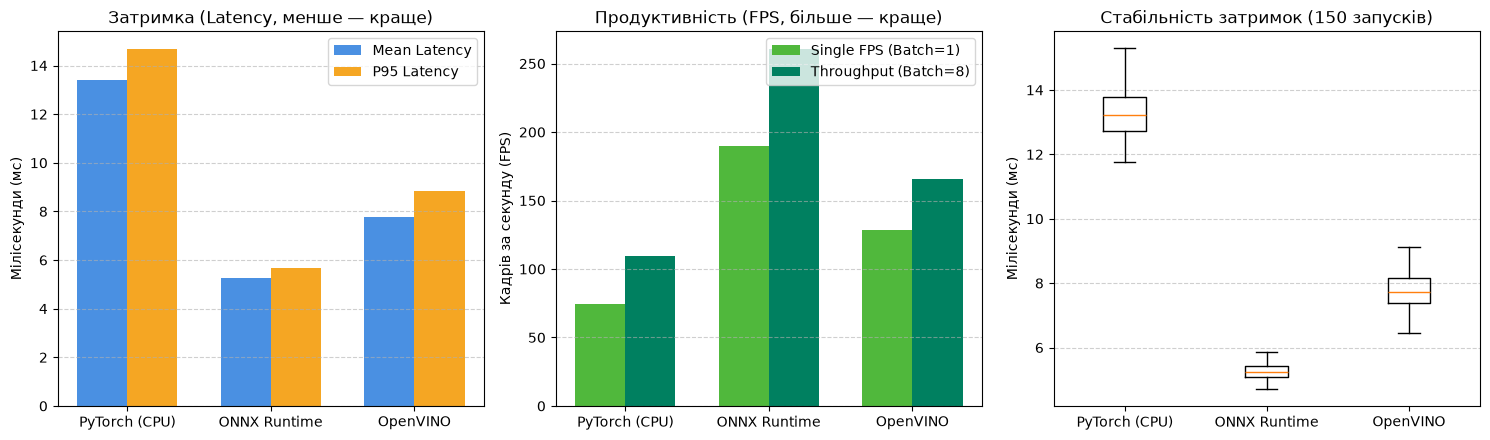

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
names = [r["name"] for r in results]
colors = ["#ee4c2c", "#005ced", "#0068b5"]

# Графік 1: Середня та P95 Latency (мс)
x = np.arange(len(names))
width = 0.35
axes[0].bar(x - width/2, [r["mean_ms"] for r in results], width, label="Mean Latency", color="#4a90e2")
axes[0].bar(x + width/2, [r["p95_ms"] for r in results], width, label="P95 Latency", color="#f5a623")
axes[0].set_title("Затримка (Latency, менше — краще)")
axes[0].set_ylabel("Мілісекунди (мс)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(names)
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Графік 2: FPS (Batch=1) vs Throughput (Batch=8)
axes[1].bar(x - width/2, [r["fps_b1"] for r in results], width, label="Single FPS (Batch=1)", color="#50b83c")
axes[1].bar(x + width/2, [r["throughput_b8"] for r in results], width, label="Throughput (Batch=8)", color="#008060")
axes[1].set_title("Продуктивність (FPS, більше — краще)")
axes[1].set_ylabel("Кадрів за секунду (FPS)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(names)
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

# Графік 3: Розподіл часу інференсу (Boxplot)
axes[2].boxplot([r["latencies"] for r in results], tick_labels=names, showfliers=False)
axes[2].set_title("Стабільність затримок (150 запусків)")
axes[2].set_ylabel("Мілісекунди (мс)")
axes[2].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()